# Calibração da regra de aceite

A seleção aceita um desafiante quando, em `V_select`, ele tem ganho mediano ≥ 1%, vence em ≥ 60% das unidades e (com corretor) corrige de fato. Isso é uma **regra de protocolo**, não um teste estatístico. Este notebook mede o comportamento dela em dois controles cuja resposta certa é conhecida:

| Controle | Série | Resposta certa | Erro medido |
|---|---|---|---|
| `white_noise` (negativo) | nível + ruído branco | ficar com um modelo individual | **falso aceite**: campeão híbrido |
| `ar_residual` (positivo) | tendência + sazonalidade + ruído AR(0,8), bases sem AR | aceitar o híbrido | **ganho útil recusado**: campeão individual |

Para cada série e número de origens em `V_select` (`fold`), a busca e a seleção rodam uma vez; cada política é aplicada aos **mesmos** finalistas. As taxas reamostram **séries** (origens de uma série não são independentes). O teste selado nunca é lido.

Dois conjuntos com sementes disjuntas: **calibração** (para olhar e decidir) e **confirmação** (para conferir uma vez).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

import autohybts
from autohybts.benchmarks.calibration import (
    calibration_protocol,
    calibration_report,
    control_cases,
    run_calibration,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Configuração

In [2]:
N_SERIES = 30  # por controle
FOLDS = (2, 3, 5)
POLICIES = {"rule": {}, "rule+wilcoxon_0.05": {"significance_alpha": 0.05}}

protocol = calibration_protocol(N_SERIES, "calibration", FOLDS, POLICIES)
print(
    "limiares:",
    {k: protocol["base_policy"][k] for k in ("median_gain_threshold", "win_rate_threshold")},
)
print("variabilidade:", protocol["base_policy"]["variability"])
print("orçamento:", protocol["budget"], "| horizonte:", protocol["fh"])

limiares: {'median_gain_threshold': 0.01, 'win_rate_threshold': 0.6}
variabilidade: {'name': 'correction_std_ratio', 'version': 2, 'threshold': 0.05, 'direction': 'gte', 'aggregation': 'median'}
orçamento: smoke | horizonte: 7


## 2. Conjunto de calibração

`hybrid_champion_rate` é a fração de séries com campeão híbrido. No controle negativo é a taxa de **falso aceite por cadeia**; no positivo, `rejected_gain_rate = 1 − taxa`. `min_one_sided_p` é o menor p-valor que o Wilcoxon consegue dar com aquele número de unidades.

In [3]:
started = time.perf_counter()
table = run_calibration(control_cases(N_SERIES, "calibration"), FOLDS, POLICIES)
print(f"{len(table)} linhas em {(time.perf_counter() - started) / 60:.1f} min")
report = calibration_report(table)
columns = [
    "kind",
    "select_units",
    "min_one_sided_p",
    "hybrid_champion_rate",
    "rate_ci_low",
    "rate_ci_high",
    "rejected_gain_rate",
]
report[columns].round(3)

360 linhas em 4.0 min


kind  select_units  min_one_sided_p  hybrid_champion_rate  rate_ci_low  rate_ci_high  rejected_gain_rate
control     fold policy                                                                                                                          
ar_residual 2    rule                positive             2            0.250                 0.267        0.133         0.433               0.733
                 rule+wilcoxon_0.05  positive             2            0.250                 0.000        0.000         0.000               1.000
            3    rule                positive             3            0.125                 0.667        0.500         0.833               0.333
                 rule+wilcoxon_0.05  positive             3            0.125                 0.000        0.000         0.000               1.000
            5    rule                positive             5            0.031                 0.867        0.733         0.967               0.133
                 rule+wilcoxon_0.05  positive             5            0.031                 0.067        0.000         0.167               0.933
white_noise 2    rule                negative             2            0.250                 0.167        0.033         0.300                 NaN
                 rule+wilcoxon_0.05  negative             2            0.250                 0.000        0.000         0.000                 NaN
            3    rule                negative             3            0.125                 0.367        0.200         0.533                 NaN
                 rule+wilcoxon_0.05  negative             3            0.125                 0.000        0.000         0.000                 NaN
            5    rule                negative             5            0.031                 0.233        0.100         0.400                 NaN
                 rule+wilcoxon_0.05  negative             5            0.031                 0.033        0.000         0.100                 NaN

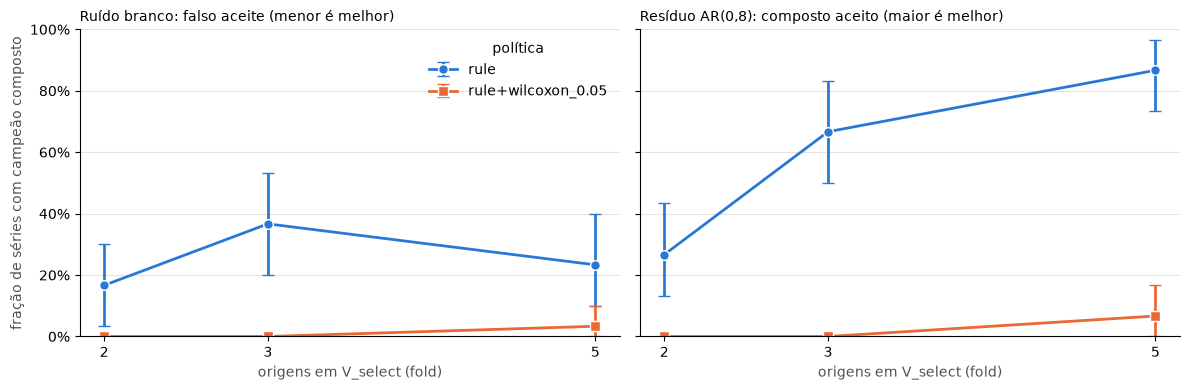

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
titles = {
    "white_noise": "Ruído branco: falso aceite (menor é melhor)",
    "ar_residual": "Resíduo AR(0,8): composto aceito (maior é melhor)",
}
colors = ["#2a78d6", "#eb6834"]  # one fixed colour per policy
for ax, control in zip(axes, ["white_noise", "ar_residual"], strict=True):
    part = report.loc[control]
    for policy, marker, color in zip(POLICIES, ["o", "s"], colors, strict=True):
        rows = part.xs(policy, level="policy")
        ax.errorbar(
            rows.index,
            rows["hybrid_champion_rate"],
            yerr=[
                rows["hybrid_champion_rate"] - rows["rate_ci_low"],
                rows["rate_ci_high"] - rows["hybrid_champion_rate"],
            ],
            marker=marker,
            markersize=7,
            markeredgecolor="white",
            color=color,
            linewidth=2,
            capsize=4,
            label=policy,
        )
    ax.set_title(titles[control], loc="left", fontsize=10)
    ax.set_xlabel("origens em V_select (fold)", color="#52514e")
    ax.set_xticks(list(FOLDS))
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("fração de séries com campeão composto", color="#52514e")
axes[0].legend(frameon=False, title="política")
fig.tight_layout()

## 3. Conjunto de confirmação

Mesmas condições, outras séries. Se uma política fosse escolhida olhando a calibração, esta seria a conferência única.

In [5]:
confirmation = calibration_report(
    run_calibration(control_cases(N_SERIES, "confirmation"), FOLDS, POLICIES)
)
side_by_side = pd.concat(
    {
        "calibração": report["hybrid_champion_rate"],
        "confirmação": confirmation["hybrid_champion_rate"],
    },
    axis=1,
)
side_by_side.round(3)

calibração  confirmação
control     fold policy                                     
ar_residual 2    rule                     0.267        0.367
                 rule+wilcoxon_0.05       0.000        0.000
            3    rule                     0.667        0.500
                 rule+wilcoxon_0.05       0.000        0.000
            5    rule                     0.867        0.667
                 rule+wilcoxon_0.05       0.067        0.100
white_noise 2    rule                     0.167        0.067
                 rule+wilcoxon_0.05       0.000        0.000
            3    rule                     0.367        0.267
                 rule+wilcoxon_0.05       0.000        0.000
            5    rule                     0.233        0.267
                 rule+wilcoxon_0.05       0.033        0.033

## 4. Leitura dos resultados

Nesta execução (30 séries por controle e conjunto, `fh=7`, orçamento `smoke`):

* **A regra aceita híbridos espúrios.** No ruído branco, o campeão é híbrido em 17% (`fold=2`), 37% (`fold=3`) e 23% (`fold=5`) das séries de calibração. A taxa não cai com mais origens de forma monótona: com 3 unidades, 60% de vitórias exige 2 de 3, mais fácil por acaso que 2 de 2.
* **Mais origens ajudam a reconhecer ganho real.** No resíduo AR(0,8), o híbrido é aceito em 27%, 67% e 87% das séries com 2, 3 e 5 origens.
* **O Wilcoxon troca um erro pelo outro.** Ele quase zera os falsos aceites (0–3%), mas recusa quase todos os ganhos úteis: com até 3 unidades ele nunca passa (p mínimo 1/4 e 1/8) e com 5 aceita 7% (calibração) ou 10% (confirmação).
* **Confirmação.** As taxas da confirmação ficam na mesma faixa, com uma exceção: no resíduo AR com `fold=5`, 67% contra 87% na calibração, abaixo do intervalo dela. Com 30 séries os intervalos são largos (±15 pontos); rode com mais séries antes de escolher uma política.

Nenhuma das duas políticas domina: escolher entre elas (ou outro `fold`, ou outros limiares) exige fixar antes qual erro é mais caro, e conferir a escolha uma única vez no conjunto de confirmação. Limites: dois controles sintéticos diários, uma comparação híbrida por cadeia, um orçamento e uma semente de sessão.